# Data Context

The data used in this notebook comes from the **Credit Card Fraud** dataset published on Kaggle by Dhanush Narayanan R:
[https://www.kaggle.com/datasets/dhanushnarayananr/credit-card-fraud/data](https://www.kaggle.com/datasets/dhanushnarayananr/credit-card-fraud/data)

The dataset contains records of individual credit card transactions. Each row is one transaction, and each column describes
something about where, how, or for how much that transaction was made. The final column records whether the transaction
turned out to be fraudulent. The data is provided in a single file, `card_transdata.csv`.

| Column | Type | Description |
|---|---|---|
| `distance_from_home` | Numeric (continuous) | The distance from the cardholder's home to the location where the transaction took place. |
| `distance_from_last_transaction` | Numeric (continuous) | The distance between the location of this transaction and the location of the cardholder's previous transaction. |
| `ratio_to_median_purchase_price` | Numeric (continuous) | The purchase price of this transaction divided by the cardholder's median purchase price. A value of 1 means a typical purchase; a value of 5 means the purchase was five times the usual amount. |
| `repeat_retailer` | Binary (0 / 1) | Whether the transaction happened at a retailer the cardholder has bought from before (1 = yes, 0 = no). |
| `used_chip` | Binary (0 / 1) | Whether the transaction was made using the card's chip (1 = yes, 0 = no). |
| `used_pin_number` | Binary (0 / 1) | Whether the transaction was made using the card's PIN number (1 = yes, 0 = no). |
| `online_order` | Binary (0 / 1) | Whether the transaction was an online order (1 = yes, 0 = no). |
| `fraud` | Binary (0 / 1) | **The target variable.** Whether the transaction was fraudulent (1 = fraud, 0 = not fraud). |

The three distance and price columns tell us *where* and *how much*, while the four yes/no columns tell us *how* the purchase was made.
Together they let us look for patterns that separate fraudulent transactions from legitimate ones.

# First Day Data Science with Python

**Author:** CJ Marshall (Dr. Amish Mishra)

**Course:** MAT311

**Date:** November 2nd, 2026

---

In this notebook we will explore **credit card fraud detection**. Credit card fraud costs consumers and banks a great deal
of money every year, and catching a fraudulent transaction quickly depends on recognizing what makes it look different from
a normal one. Using a dataset of credit card transactions, we will load and inspect the raw data, clean it, and then build
a series of visualizations, first looking at each variable on its own and then comparing each variable against whether the
transaction was fraudulent. The goal is to use Python to understand and model the data so we can turn it into valuable
insights: which purchasing behaviors (using a PIN, using a chip, ordering online, spending far more than usual, or buying
far from home) are most associated with fraud.

# Load the Data

In [1]:
# Import the libraries we will use throughout the notebook
import pandas as pd               # pandas: loading, cleaning, and summarizing tabular data
import seaborn as sns             # seaborn: statistical plots built on top of matplotlib
import matplotlib.pyplot as plt   # matplotlib.pyplot: figure creation, titles, and axis labels
import plotly.express as px       # plotly.express: interactive plotting

In [2]:
# Load the dataset from the CSV file into a pandas DataFrame
df = pd.read_csv("card_transdata.csv")

# Display the first five rows of the raw data
df.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


In [3]:
# Show the shape of the raw data as (number of rows, number of columns)
df.shape

(1000000, 8)

In [4]:
# Show the info of the raw data: column names, non-null counts, and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non-null  float64
 6   online_order                    1000000 non-null  float64
 7   fraud                           1000000 non-null  float64
dtypes: float64(8)
memory usage: 61.0 MB


In [5]:
# Describe the raw data: count, mean, standard deviation, min, quartiles, and max for each column
df.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,26.628792,5.036519,1.824182,0.881536,0.350399,0.100608,0.650552,0.087403
std,65.390784,25.843093,2.799589,0.323157,0.477095,0.300809,0.476796,0.282425
min,0.004874,0.000118,0.004399,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.878008,0.296671,0.475673,1.000000,0.000000,0.000000,0.000000,0.000000
50%,9.967760,0.998650,0.997717,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.743985,3.355748,2.096370,1.000000,1.000000,0.000000,1.000000,0.000000
max,10632.723672,11851.104565,267.802942,1.000000,1.000000,1.000000,1.000000,1.000000


# Data Wrangling

In [6]:
# Count how many null (missing) values are in each column
df.isnull().sum()

distance_from_home                0
distance_from_last_transaction    0
ratio_to_median_purchase_price    0
repeat_retailer                   0
used_chip                         0
used_pin_number                   0
online_order                      0
fraud                             0
dtype: int64

### Handling null values

Null values are entries where data is missing. Before we visualize or model the data we need to decide what to do with them,
because many plotting and modeling functions either fail or quietly give misleading results when values are missing. The most
common options are:

- **Drop** the rows (or columns) that contain null values. This is simple and works well when only a small share of rows is
  affected, or when the dataset is large enough that losing a few rows does not matter.
- **Fill (impute)** the missing values with a substitute, such as the mean or median for numeric columns, or the most common
  value for categorical columns. This keeps every row but can distort the data if many values are missing.
- **Flag** the missing values with a separate indicator column, when the fact that a value is missing might itself be meaningful.

Because this dataset is large, we will take the simplest approach and drop any rows that contain null values.
In this dataset the null count above shows **zero** missing values in every column, so dropping nulls leaves all
1,000,000 rows in place. It is still good practice to include this step so the notebook stays correct if it is ever run on
a version of the data that does have missing entries.

In [7]:
# Clean the data by dropping every row that contains at least one null value
df_clean = df.dropna()

# Print the new shape of the cleaned dataset
print("Shape of cleaned data:", df_clean.shape)

# Display the first five rows of the cleaned data
df_clean.head()

Shape of cleaned data: (1000000, 8)


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


# Visualizing the Data

We start with **univariate** plots, which look at one variable at a time. All plots use the cleaned dataset `df_clean`.

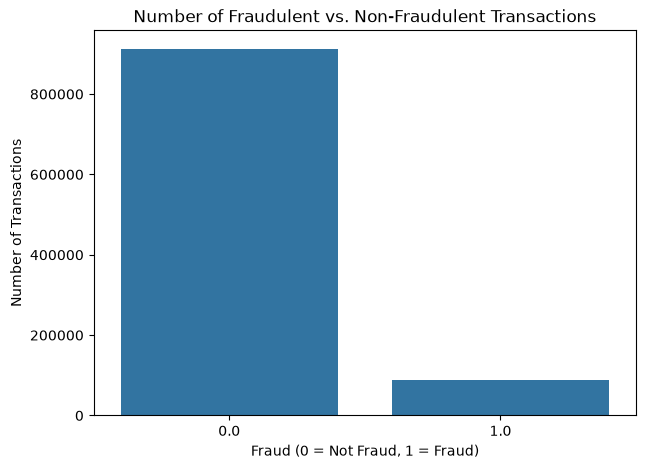

In [8]:
# Count plot of the fraud column: how many transactions were fraud (1) versus not fraud (0)
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="fraud")         # one bar per category, bar height = number of rows
plt.title("Number of Fraudulent vs. Non-Fraudulent Transactions")
plt.xlabel("Fraud (0 = Not Fraud, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

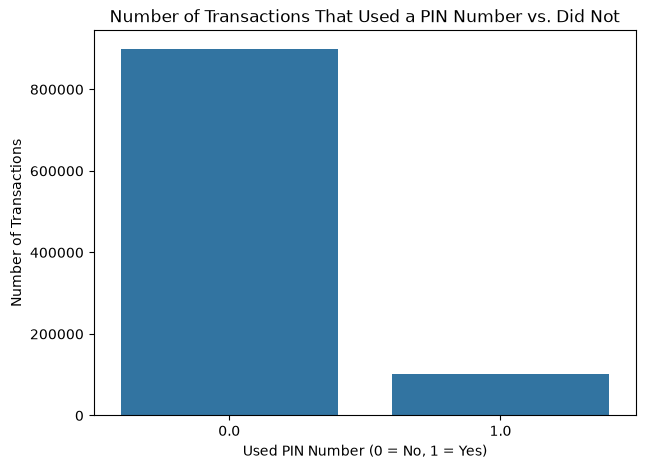

In [9]:
# Count plot of the used_pin_number column: transactions that used a PIN (1) versus did not (0)
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="used_pin_number")
plt.title("Number of Transactions That Used a PIN Number vs. Did Not")
plt.xlabel("Used PIN Number (0 = No, 1 = Yes)")
plt.ylabel("Number of Transactions")
plt.show()

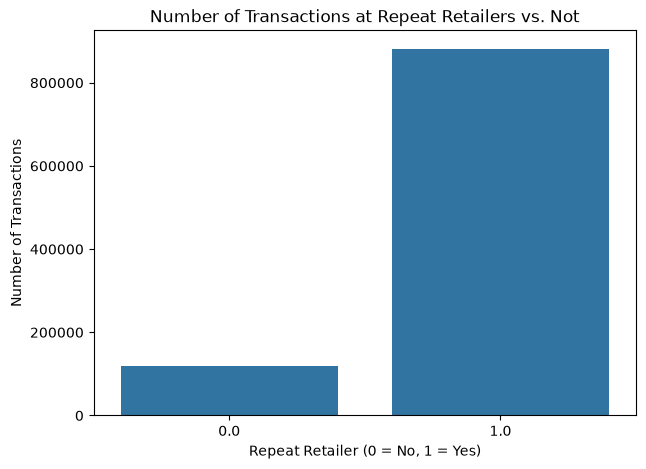

In [10]:
# Count plot of the repeat_retailer column: transactions at a repeat retailer (1) versus a new retailer (0)
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="repeat_retailer")
plt.title("Number of Transactions at Repeat Retailers vs. Not")
plt.xlabel("Repeat Retailer (0 = No, 1 = Yes)")
plt.ylabel("Number of Transactions")
plt.show()

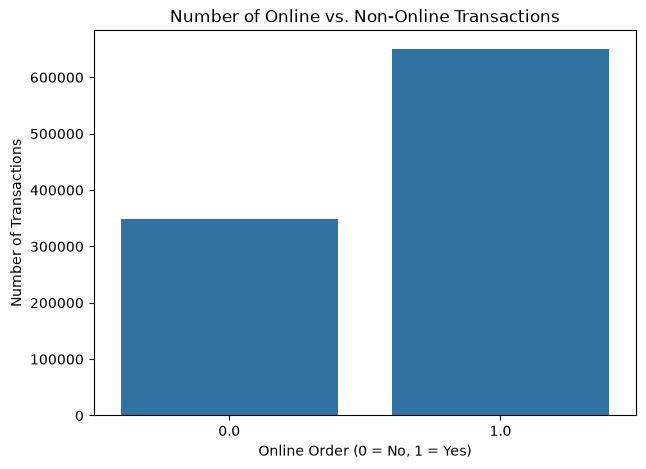

In [11]:
# Count plot of the online_order column: online transactions (1) versus in-person transactions (0)
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="online_order")
plt.title("Number of Online vs. Non-Online Transactions")
plt.xlabel("Online Order (0 = No, 1 = Yes)")
plt.ylabel("Number of Transactions")
plt.show()

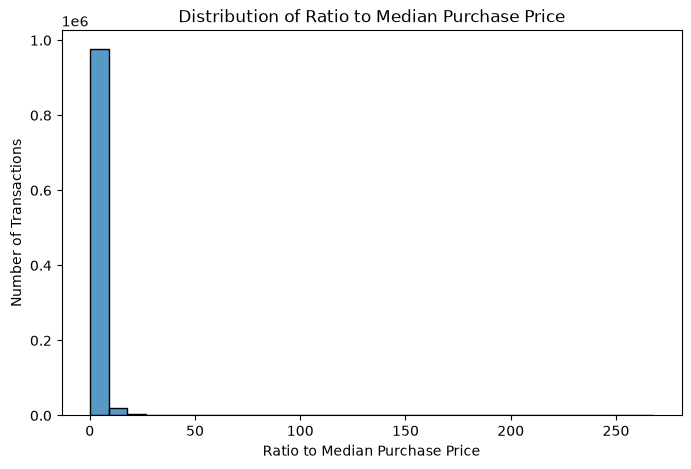

In [12]:
# Histogram of ratio_to_median_purchase_price with 30 bins
# This shows the distribution of how large each purchase was compared to the cardholder's typical purchase
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="ratio_to_median_purchase_price", bins=30)
plt.title("Distribution of Ratio to Median Purchase Price")
plt.xlabel("Ratio to Median Purchase Price")
plt.ylabel("Number of Transactions")
plt.show()

# Better Visualizations: Bivariate Visualizations

Now we compare each variable against **fraud**. In every plot, **green = not fraudulent** and **red = fraudulent**.
Each variable gets two plots: a side-by-side count plot showing the raw counts, and a stacked percentage plot showing
what share of each group was fraudulent. The percentage plot is useful because the groups can be very different sizes.

In [13]:
# Color palette used for every bivariate plot: 0 (not fraud) = green, 1 (fraud) = red
fraud_colors = {0: "green", 1: "red"}

### PIN number vs. fraud

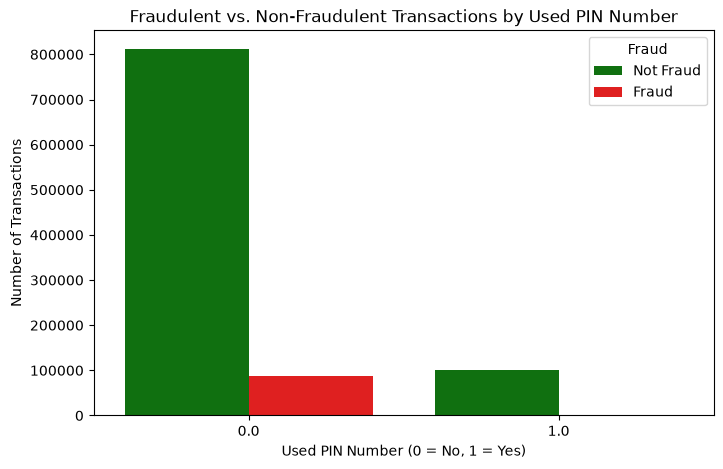

In [14]:
# Side-by-side count plot of used_pin_number, split by fraud
# x-axis = whether a PIN number was used; hue splits each bar into not fraud (green) and fraud (red)
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="used_pin_number", hue="fraud", palette=fraud_colors)
plt.title("Fraudulent vs. Non-Fraudulent Transactions by Used PIN Number")
plt.xlabel("Used PIN Number (0 = No, 1 = Yes)")
plt.ylabel("Number of Transactions")
plt.legend(title="Fraud", labels=["Not Fraud", "Fraud"])
plt.show()

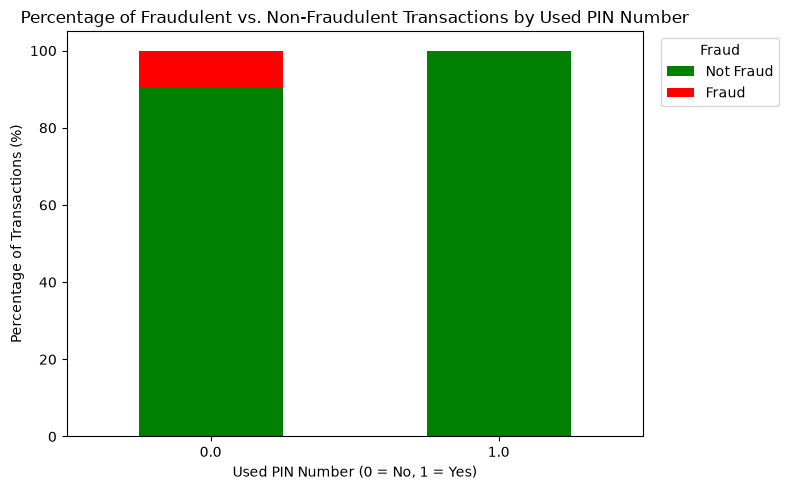

In [15]:
# Stacked percentage plot of used_pin_number, split by fraud
# pd.crosstab counts fraud / not fraud within each used_pin_number group;
# normalize="index" turns each row into proportions that add to 1, and * 100 converts them to percentages
used_pin_number_pct = pd.crosstab(df_clean["used_pin_number"], df_clean["fraud"], normalize="index") * 100

# Plot the percentages as stacked bars so each bar adds to 100% (green = not fraud, red = fraud)
used_pin_number_pct.plot(kind="bar", stacked=True, color=["green", "red"], figsize=(8, 5))
plt.title("Percentage of Fraudulent vs. Non-Fraudulent Transactions by Used PIN Number")
plt.xlabel("Used PIN Number (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Transactions (%)")
plt.xticks(rotation=0)
plt.legend(title="Fraud", labels=["Not Fraud", "Fraud"], bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Chip vs. fraud

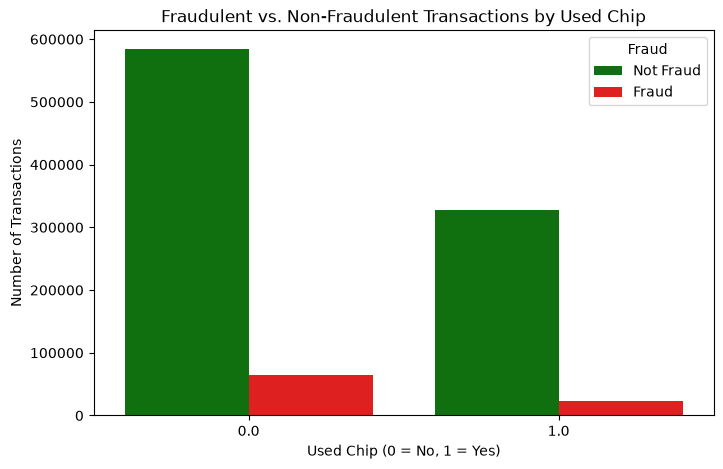

In [16]:
# Side-by-side count plot of used_chip, split by fraud
# x-axis = whether the card's chip was used; hue splits each bar into not fraud (green) and fraud (red)
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="used_chip", hue="fraud", palette=fraud_colors)
plt.title("Fraudulent vs. Non-Fraudulent Transactions by Used Chip")
plt.xlabel("Used Chip (0 = No, 1 = Yes)")
plt.ylabel("Number of Transactions")
plt.legend(title="Fraud", labels=["Not Fraud", "Fraud"])
plt.show()

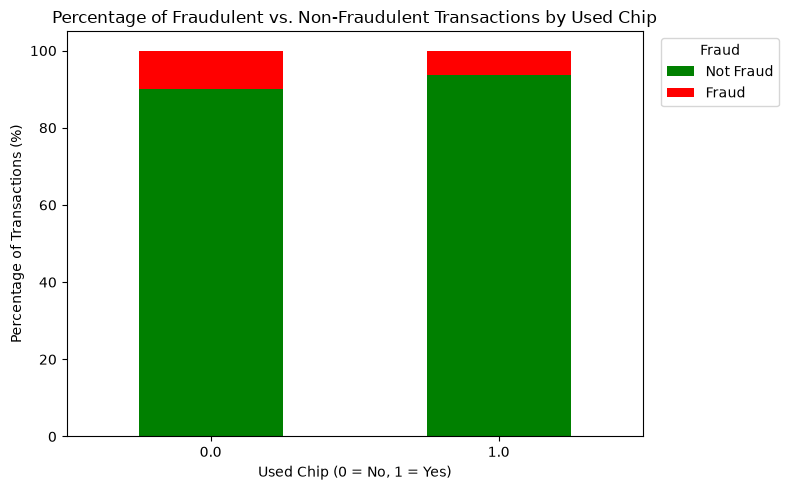

In [17]:
# Stacked percentage plot of used_chip, split by fraud
# pd.crosstab counts fraud / not fraud within each used_chip group;
# normalize="index" turns each row into proportions that add to 1, and * 100 converts them to percentages
used_chip_pct = pd.crosstab(df_clean["used_chip"], df_clean["fraud"], normalize="index") * 100

# Plot the percentages as stacked bars so each bar adds to 100% (green = not fraud, red = fraud)
used_chip_pct.plot(kind="bar", stacked=True, color=["green", "red"], figsize=(8, 5))
plt.title("Percentage of Fraudulent vs. Non-Fraudulent Transactions by Used Chip")
plt.xlabel("Used Chip (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Transactions (%)")
plt.xticks(rotation=0)
plt.legend(title="Fraud", labels=["Not Fraud", "Fraud"], bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Online order vs. fraud

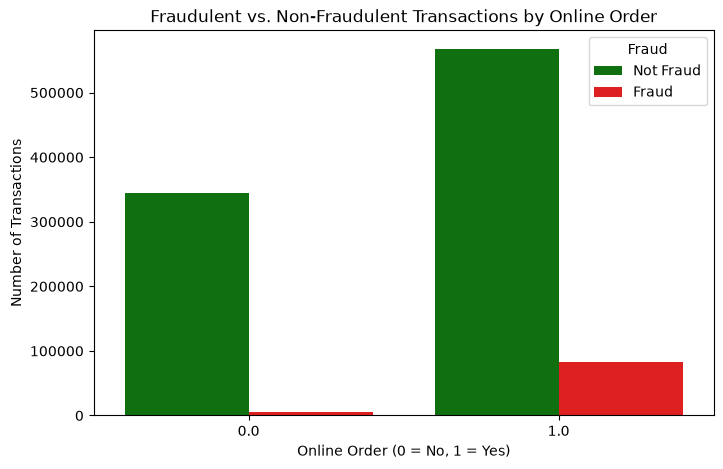

In [18]:
# Side-by-side count plot of online_order, split by fraud
# x-axis = whether the transaction was an online order; hue splits each bar into not fraud (green) and fraud (red)
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="online_order", hue="fraud", palette=fraud_colors)
plt.title("Fraudulent vs. Non-Fraudulent Transactions by Online Order")
plt.xlabel("Online Order (0 = No, 1 = Yes)")
plt.ylabel("Number of Transactions")
plt.legend(title="Fraud", labels=["Not Fraud", "Fraud"])
plt.show()

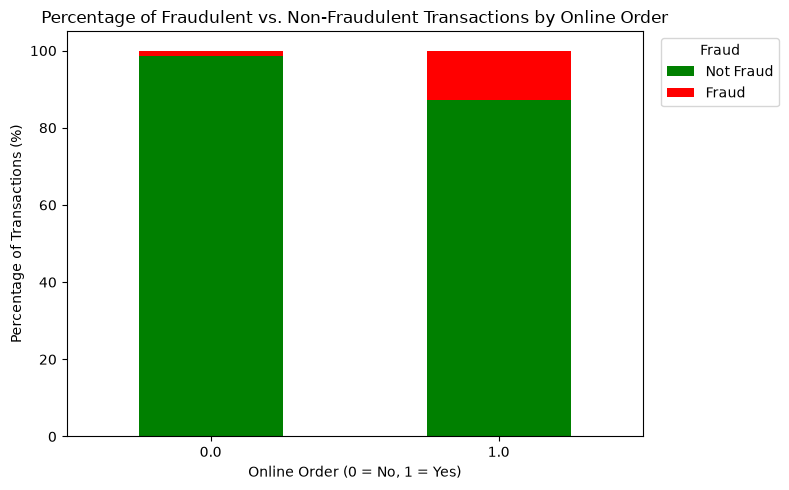

In [19]:
# Stacked percentage plot of online_order, split by fraud
# pd.crosstab counts fraud / not fraud within each online_order group;
# normalize="index" turns each row into proportions that add to 1, and * 100 converts them to percentages
online_order_pct = pd.crosstab(df_clean["online_order"], df_clean["fraud"], normalize="index") * 100

# Plot the percentages as stacked bars so each bar adds to 100% (green = not fraud, red = fraud)
online_order_pct.plot(kind="bar", stacked=True, color=["green", "red"], figsize=(8, 5))
plt.title("Percentage of Fraudulent vs. Non-Fraudulent Transactions by Online Order")
plt.xlabel("Online Order (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Transactions (%)")
plt.xticks(rotation=0)
plt.legend(title="Fraud", labels=["Not Fraud", "Fraud"], bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Scatter plots

Finally, we compare two continuous variables at once and color each transaction by whether it was fraudulent.
Because there are 1,000,000 overlapping points, we draw the fraudulent transactions first and the non-fraudulent transactions on top, so red only shows where fraud is not hidden by normal transactions.

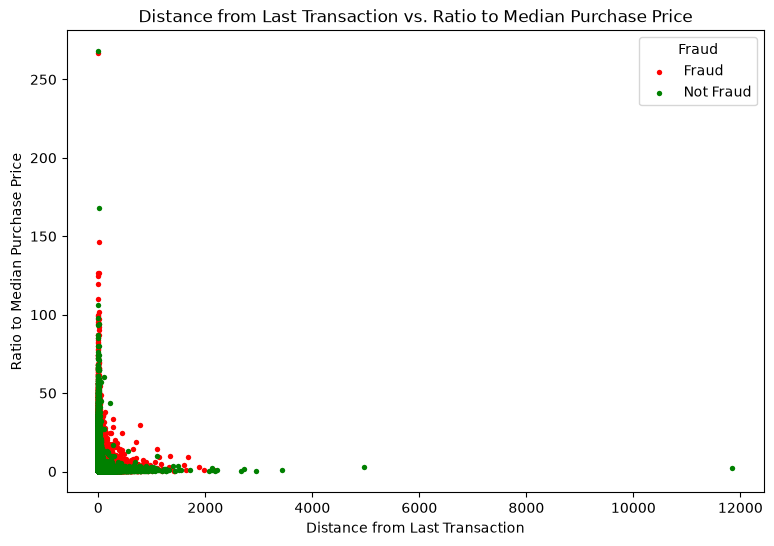

In [20]:
# Scatter plot: distance from last transaction (x) vs. ratio to median purchase price (y)
# Each dot is one transaction, colored red (fraud) or green (not fraud).
# With 1,000,000 overlapping points, draw order decides which color shows where dots overlap,
# so we split the data and draw it in two layers:
#   1) fraudulent transactions first (red)
#   2) non-fraudulent transactions second, on top (green)
fraud_df = df_clean[df_clean["fraud"] == 1]
not_fraud_df = df_clean[df_clean["fraud"] == 0]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=fraud_df, x="distance_from_last_transaction", y="ratio_to_median_purchase_price",
                color="red", s=15, linewidth=0, label="Fraud")
sns.scatterplot(data=not_fraud_df, x="distance_from_last_transaction", y="ratio_to_median_purchase_price",
                color="green", s=15, linewidth=0, label="Not Fraud")
plt.title("Distance from Last Transaction vs. Ratio to Median Purchase Price")
plt.xlabel("Distance from Last Transaction")
plt.ylabel("Ratio to Median Purchase Price")
plt.legend(title="Fraud", loc="upper right")
plt.show()

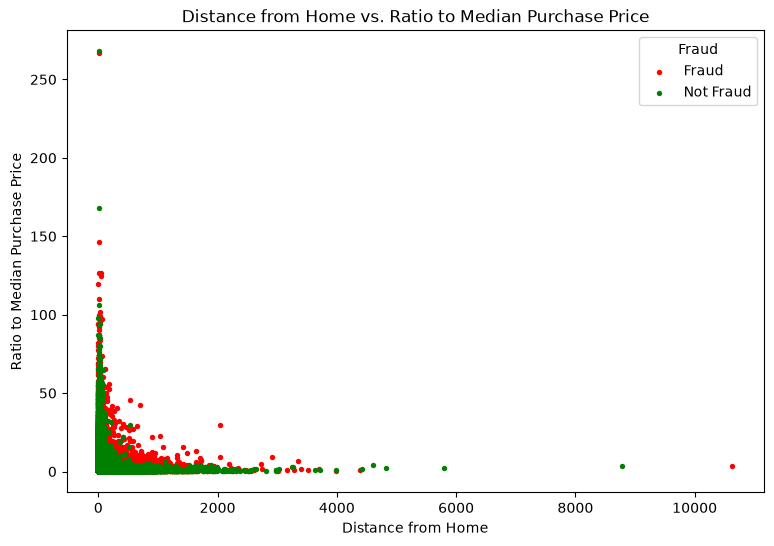

In [21]:
# Scatter plot: distance from home (x) vs. ratio to median purchase price (y)
# Each dot is one transaction, colored red (fraud) or green (not fraud).
# With 1,000,000 overlapping points, draw order decides which color shows where dots overlap,
# so we split the data and draw it in two layers:
#   1) fraudulent transactions first (red)
#   2) non-fraudulent transactions second, on top (green)
fraud_df = df_clean[df_clean["fraud"] == 1]
not_fraud_df = df_clean[df_clean["fraud"] == 0]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=fraud_df, x="distance_from_home", y="ratio_to_median_purchase_price",
                color="red", s=15, linewidth=0, label="Fraud")
sns.scatterplot(data=not_fraud_df, x="distance_from_home", y="ratio_to_median_purchase_price",
                color="green", s=15, linewidth=0, label="Not Fraud")
plt.title("Distance from Home vs. Ratio to Median Purchase Price")
plt.xlabel("Distance from Home")
plt.ylabel("Ratio to Median Purchase Price")
plt.legend(title="Fraud", loc="upper right")
plt.show()